### Imports & Setup

In [1]:
import os
import time
import subprocess
import numpy as np
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

from model import CifarTinyNet


### Dataset Load

In [2]:
DATA_ROOT = "../data"

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

assert os.path.exists(os.path.join(DATA_ROOT, "cifar-10-batches-py")), \
       "CIFAR-10 dataset not found. Run train_and_export.ipynb first."

testset = torchvision.datasets.CIFAR10(
    root=DATA_ROOT,
    train=False,
    download=False,
    transform=transform
)

class_names = testset.classes


### Select 10 REAL Test Images

In [3]:
NUM_SAMPLES = 10

test_images = []
test_labels = []

for i in range(NUM_SAMPLES):
    img, label = testset[i]
    test_images.append(img.unsqueeze(0))  # shape: [1, 3, 32, 32]
    test_labels.append(label)

print("Selected test labels:")
for i, lbl in enumerate(test_labels):
    print(f"Image {i}: {class_names[lbl]}")


Selected test labels:
Image 0: cat
Image 1: ship
Image 2: ship
Image 3: airplane
Image 4: frog
Image 5: frog
Image 6: automobile
Image 7: frog
Image 8: cat
Image 9: automobile


### Load PyTorch Model (CPU)

In [4]:
model = CifarTinyNet()
model.load_state_dict(
    torch.load("../models/cifar_tinynet.pth", map_location="cpu")
)
model.eval()


CifarTinyNet(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=1152, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=10, bias=True)
)

### Python Inference Benchmark (Steady-State)

In [5]:
def benchmark_python(model, inputs, runs=500):
    latencies = []

    # Warm-up
    for _ in range(50):
        _ = model(inputs[0])

    for idx, x in enumerate(inputs):
        times = []
        for _ in range(runs):
            start = time.perf_counter()
            _ = model(x)
            end = time.perf_counter()
            times.append((end - start) * 1000)  # ms

        avg_time = np.mean(times)
        latencies.append(avg_time)
        print(f"Python | Image {idx} Avg Latency: {avg_time:.3f} ms")

    return latencies


### Run Python Benchmark

In [6]:
python_latencies = benchmark_python(model, test_images)


Python | Image 0 Avg Latency: 0.365 ms
Python | Image 1 Avg Latency: 0.442 ms
Python | Image 2 Avg Latency: 0.387 ms
Python | Image 3 Avg Latency: 0.338 ms
Python | Image 4 Avg Latency: 0.324 ms
Python | Image 5 Avg Latency: 0.327 ms
Python | Image 6 Avg Latency: 0.329 ms
Python | Image 7 Avg Latency: 0.327 ms
Python | Image 8 Avg Latency: 0.338 ms
Python | Image 9 Avg Latency: 0.321 ms


### C++ Benchmark via Binary Call

In [7]:
# C++ binary prints exactly one line like:
# C++ Avg Latency (steady-state): 0.081 ms

CPP_BINARY = "../cpp/build/cifar_infer"

assert os.path.exists(CPP_BINARY), "C++ binary not found. Build it first."

def benchmark_cpp(num_runs):
    latencies = []

    for i in range(num_runs):
        result = subprocess.run(
            [CPP_BINARY],
            capture_output=True,
            text=True
        )

        for line in result.stdout.splitlines():
            if "Avg Latency" in line:
                value = float(line.split()[-2])
                latencies.append(value)
                print(f"C++ | Run {i} Avg Latency: {value:.3f} ms")

    return latencies


### Run C++ Benchmark

In [8]:
cpp_latencies = benchmark_cpp(NUM_SAMPLES)


C++ | Run 0 Avg Latency: 0.102 ms
C++ | Run 1 Avg Latency: 0.110 ms
C++ | Run 2 Avg Latency: 0.101 ms
C++ | Run 3 Avg Latency: 0.097 ms
C++ | Run 4 Avg Latency: 0.101 ms
C++ | Run 5 Avg Latency: 0.113 ms
C++ | Run 6 Avg Latency: 0.098 ms
C++ | Run 7 Avg Latency: 0.100 ms
C++ | Run 8 Avg Latency: 0.101 ms
C++ | Run 9 Avg Latency: 0.097 ms


### Summary Statistics

In [9]:
print("\n=== Summary Statistics ===")

print(f"Python Mean Latency : {np.mean(python_latencies):.3f} ms")
print(f"Python Std Dev      : {np.std(python_latencies):.3f} ms")

print(f"C++ Mean Latency    : {np.mean(cpp_latencies):.3f} ms")
print(f"C++ Std Dev         : {np.std(cpp_latencies):.3f} ms")



=== Summary Statistics ===
Python Mean Latency : 0.350 ms
Python Std Dev      : 0.037 ms
C++ Mean Latency    : 0.102 ms
C++ Std Dev         : 0.005 ms


### Line Plot (Per-Image Comparison)

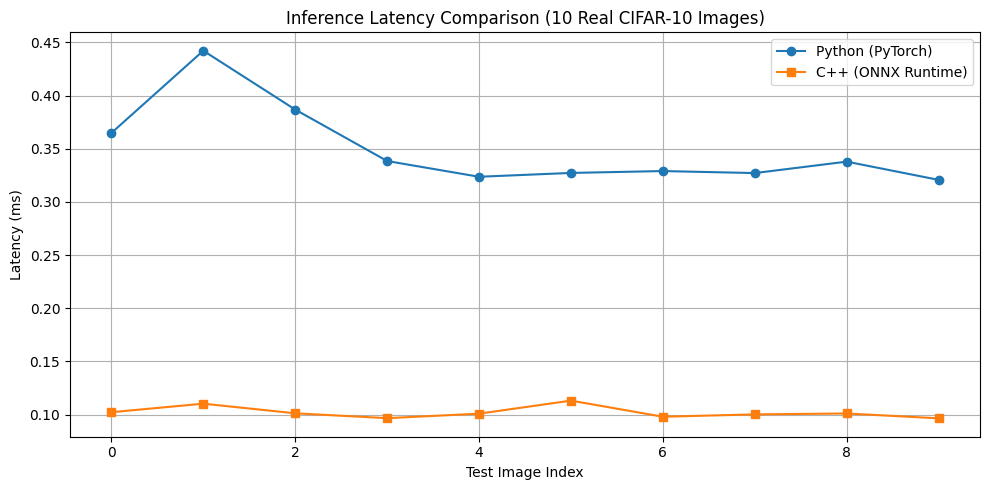

In [10]:
x = np.arange(NUM_SAMPLES)

plt.figure(figsize=(10, 5))
plt.plot(x, python_latencies, marker="o", label="Python (PyTorch)")
plt.plot(x, cpp_latencies, marker="s", label="C++ (ONNX Runtime)")

plt.xlabel("Test Image Index")
plt.ylabel("Latency (ms)")
plt.title("Inference Latency Comparison (10 Real CIFAR-10 Images)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Bar Chart

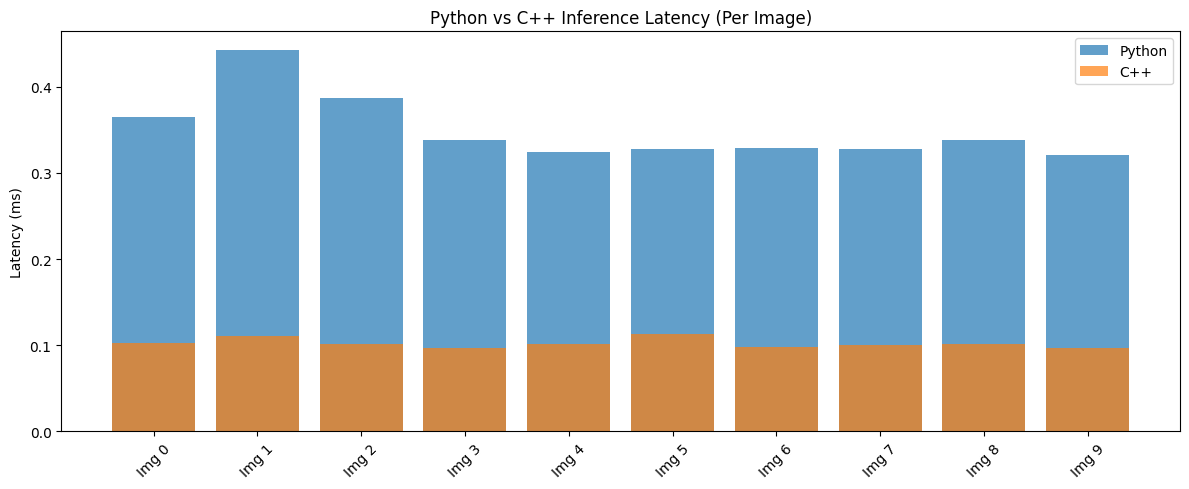

In [11]:
labels = [f"Img {i}" for i in range(NUM_SAMPLES)]

plt.figure(figsize=(12, 5))
plt.bar(labels, python_latencies, alpha=0.7, label="Python")
plt.bar(labels, cpp_latencies, alpha=0.7, label="C++")

plt.ylabel("Latency (ms)")
plt.title("Python vs C++ Inference Latency (Per Image)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

os.makedirs("../results", exist_ok=True)
plt.savefig("../results/latency_comparison.png")
plt.show()
